# Giorno 1, mattina: Python essenziale

Python e Analisi Dati per Ricercatori CNR, 4 giorni da 6 ore

---

## Benvenuti

Alla fine di oggi ognuno di voi avrà scritto uno script che legge un file di dati
prodotto da uno strumento, ne estrae le informazioni utili e produce un grafico di
controllo. Domani sostituiremo un foglio Excel con qualche riga di codice; dopodomani
faremo una figura da rivista e una retta di taratura con le incertezze; l'ultimo giorno
PCA e un modello predittivo, e soprattutto impareremo a capire quando *non* fidarci del risultato.

### Una cosa da dire subito

Tutti voi lavorate con i dati da anni. Nei prossimi giorni vi capiterà di sapere esattamente cosa volete ottenere
e di non riuscire a scriverlo: è normale, e passa con la pratica. Per questo gran parte
del corso è fatta di esercizi.

### Cosa NON faremo (e perché)

| Escluso | Motivo |
|---|---|
| Reti neurali / deep learning | Non si insegna onestamente in 4 giorni; con pochi campioni è pericoloso |
| Assistenti LLM per il codice | Prima bisogna saper leggere e verificare il codice.  |
| Git, VS Code | Restiamo su Jupyter tutti e quattro i giorni |
| Bioinformatica specifica (FASTA, VCF, Biopython, scanpy) | Ogni formato ha le sue librerie; pandas e NumPy di questi giorni sono la base comune |

### Python o R?

Molti di voi usano già R. Non si tratta di sostituirlo, ma di aggiungere uno strumento: i due
convivono benissimo (si passano file CSV, e si chiamano a vicenda con `rpy2` e `reticulate`).

| Python è più comodo per… | R resta più comodo per… |
|---|---|
| procurarsi e preparare i dati: molti file, API e database, automatizzare | statistica classica e modelli misti (`lm`, `lme4`), con la sintassi a formula |
| machine learning e deep learning (scikit-learn, PyTorch), analisi di immagini | Bioconductor (DESeq2, limma, edgeR: espressione differenziale) |
| pipeline e strumenti (Snakemake è Python), dati single-cell molto grandi (scanpy) | ggplot2, report in RMarkdown/Quarto |
| un linguaggio generale: lo stesso codice diventa uno script, un servizio, uno strumento per il laboratorio | molti metodi statistici nuovi escono prima come pacchetti R |

Un criterio pratico: se il vostro tempo va soprattutto in modelli statistici su tabelle già
pulite, R va benissimo; se va nel procurarvi, unire e pulire i dati, nell'automazione, nell'ML o nelle
pipeline, Python vi farà risparmiare tempo. Il test migliore: nei prossimi giorni rifate in Python
un'analisi che fate già in R, e confrontate.

### Regole d'aula

- Potete lavorare da soli o in coppia, come preferite.
- È normale non finire tutti gli esercizi. Ogni esercizio ha in fondo un'*estensione facoltativa*
  per chi finisce presto.
- Sotto ogni esercizio c'è l'output atteso: se il vostro coincide, avete finito.

---
## 0. Cella di avvio

Ogni notebook del corso inizia con questa cella. Eseguitela sempre per prima
(`Shift + Invio`): trova la cartella dei dati e, se non c'è, la rigenera.

In [ ]:
from pathlib import Path
import sys

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    # non trovata (es. Google Colab): la rigeneriamo dallo script del corso
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
print("Cartella dati:", DATI.resolve())
print("Python:", sys.version.split()[0])

---
## 1. JupyterLab: celle, kernel, ordine di esecuzione

Un notebook è una sequenza di **celle**, di due tipi:
- celle di testo (Markdown), come questa;
- celle di codice, che si eseguono con `Shift + Invio`.

Il codice gira in un programma separato chiamato **kernel**, che ricorda tutto quello
che avete eseguito: le variabili definite in una cella esistono nelle successive.

### I tre tranelli tipici

1. Conta l'ordine di esecuzione, non quello sulla pagina. Se eseguite la cella 5 prima
   della 3, il kernel ha visto prima la 5. Il numero tra parentesi quadre a sinistra (`[7]`)
   dice in che ordine è stata eseguita ogni cella.
2. Le variabili "fantasma": avete definito `x`, poi avete cancellato la cella. `x` esiste
   ancora nel kernel; riaprendo il notebook domani non ci sarà più e il codice fallirà.
3. Il kernel bloccato (una cella con `[*]` che non finisce mai): menu
   *Kernel → Interrupt*, oppure *Kernel → Restart*.

Prima di consegnare o salvare un notebook: *Kernel → Restart Kernel and Run All Cells*.
Se gira da cima a fondo senza errori, è **riproducibile**.

In [ ]:
# Esegui questa cella con Shift + Invio. Il risultato dell'ultima riga viene mostrato.
2 + 3

In [ ]:
# print() mostra qualunque cosa, anche nel mezzo di una cella
print("Ciao!")
print(2 + 3)
7 * 6

> Prova tu (2'): crea una nuova cella sotto questa (tasto `B` con la cella selezionata,
> oppure `+` nella barra), scrivi `10 / 4` ed eseguila. Poi cambia il tipo della cella in
> Markdown (tasto `M`) e scrivi il tuo nome.

---
## 2. Variabili e tipi

Una variabile è un nome attaccato a un valore. In Excel scrivete un valore in una cella
e la chiamate `B3`; qui scegliete voi il nome.

| In Excel | In Python |
|---|---|
| Cella B3 = 25.4 | `conc = 25.4` |
| `=B3*2` | `conc * 2` |
| Formato cella "Numero" / "Testo" | il **tipo** del valore: `float`, `int`, `str` |

I tipi che useremo di continuo:
- `int`: intero, `3`, `-12`
- `float`: numero decimale, scritto con il punto e non con la virgola: `25.4`, `1e-6`
- `str`: testo, tra virgolette: `"foglia"`, `'C001'`
- `bool`: vero/falso, `True`, `False` # mi raccomando la maiuscola

La funzione `type()` vi dice il tipo. Gran parte degli errori del primo giorno è un
problema di tipo: un numero che in realtà è testo. Si converte con `int()`, `float()`, `str()`.

In [ ]:
conc = 25.4              # µg/L
volume_mL = 50
analita = "Cu"
valido = True

print(type(conc), type(volume_mL), type(analita), type(valido))

In [ ]:
# Le operazioni fra numeri funzionano come vi aspettate
massa_ug = conc * volume_mL / 1000
print(massa_ug)

# Attenzione: "25.4" tra virgolette è TESTO, non un numero
conc_testo = "25.4"
print(conc_testo * 2)          # ripete la stringa! non è un errore, ma non è quello che volevate

In [ ]:
# Conversione fra tipi: float(), int(), str()
print(float(conc_testo) * 2)
print(int(3.99))               # tronca, non arrotonda
print(round(3.456, 2))
print(str(42) + " campioni")   # per attaccare testo e numeri serve che siano entrambi testo...

### f-string: testo con numeri dentro

Mettete una `f` prima delle virgolette e le variabili tra graffe. Dopo i due punti si
specifica il formato: `.2f` = due decimali, `.3g` = tre cifre significative, `.1%` = percentuale.

In [ ]:
print(f"Campione {analita}: {conc} µg/L in {volume_mL} mL")
print(f"Massa: {massa_ug:.3f} µg")
print(f"Concentrazione: {conc:.3g} µg/L, recupero {0.8734:.1%}")

### Esercizio 1.1: riscaldamento con le conversioni (livello 1)

Il rame ha massa molare 63.55 g/mol. Convertite una concentrazione da µg/L a nmol/L
e stampate il risultato con una f-string, con 1 decimale.

Ricordate: µg/L ÷ (g/mol) = µmol/L; × 1000 = nmol/L.

In [ ]:
# ESERCIZIO 1.1 (livello 1): sostituisci i ____
massa_molare_Cu = 63.55     # g/mol
conc_ug_L = 25.4
conc_nM = conc_ug_L / ____ * ____
print(f"Cu: {conc_ug_L} µg/L = {conc_nM:____} nmol/L")


**Output atteso**

```
Cu: 25.4 µg/L = 399.7 nmol/L
```

---
## 3. Liste: la prima struttura per una serie di misure

Una lista è una sequenza ordinata di valori, tra parentesi quadre. Somiglia a
una colonna di Excel, ma può contenere di tutto.

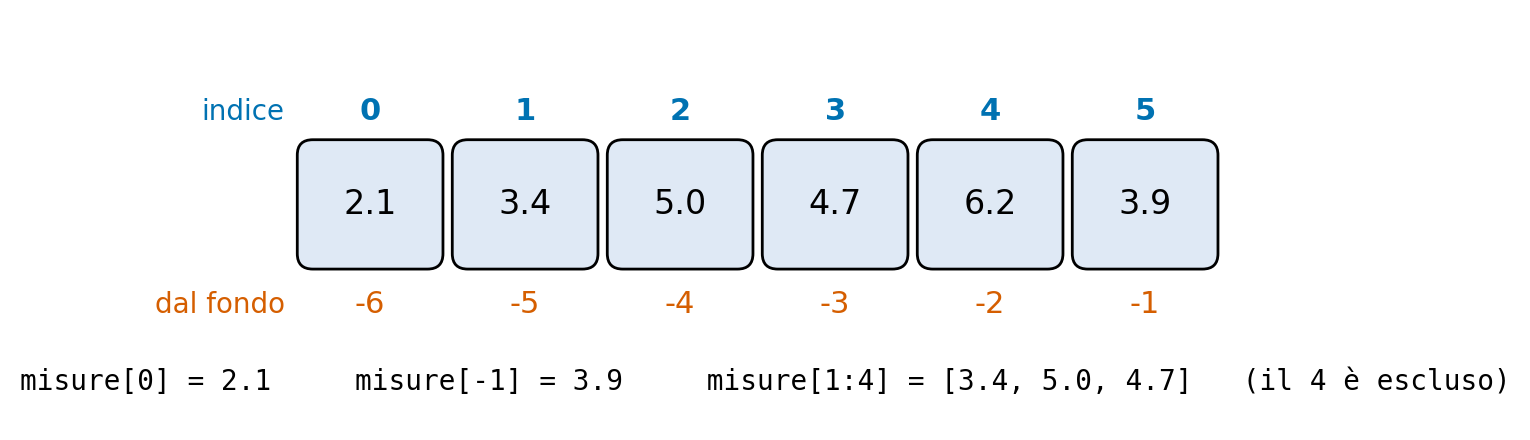

Due cose da fissare bene:
- **Si conta da 0.** Il primo elemento è `[0]`, l'ultimo è `[-1]`.
- Lo *slicing* `[a:b]` prende da `a` incluso a `b` escluso: `[1:4]` sono 3 elementi.

In [ ]:
misure = [2.1, 3.4, 5.0, 4.7, 6.2, 3.9]

print(misure[0])         # primo
print(misure[-1])        # ultimo
print(misure[1:4])       # dal secondo al quarto (indici 1, 2, 3)
print(misure[:3])        # i primi tre
print(misure[3:])        # dal quarto in poi
print(len(misure))       # quanti sono

In [ ]:
# Le funzioni base che in Excel sarebbero SOMMA, MEDIA, MIN, MAX, CONTA
print(sum(misure), min(misure), max(misure), len(misure))
print(sum(misure) / len(misure))     # la media (non c'è una funzione media in Python base)

In [ ]:
# Le liste si MODIFICANO: append aggiunge in fondo, si può riassegnare un elemento
misure.append(4.4)
misure[0] = 2.0
print(misure)
print(sorted(misure))     # copia ordinata (misure resta com'è)

### Tuple

Una tupla è una lista che non si può modificare, tra parentesi tonde. Le userete
soprattutto come *valore di ritorno* di funzioni (`shape` di un array, coppie `(x, y)`).
Si "spacchetta" assegnando a più nomi contemporaneamente.

In [ ]:
coordinate = (43.77, 11.25)
lat, lon = coordinate            # spacchettamento
print(lat, lon)

### Esercizio 1.2: manipolare una lista di misure (livello 2)

Avete le correnti di picco (µA) di 8 repliche: `[3.21, 3.35, 3.18, 9.80, 3.30, 3.27, 3.19, 3.33]`.

1. Stampate quante misure ci sono e la media.
2. Un valore è chiaramente anomalo. Ordinate la lista e stampate le prime 7 (cioè
   tutte tranne la più grande).
3. Calcolate la media senza l'anomalo.

In [ ]:
# ESERCIZIO 1.2 (livello 2)
correnti = [3.21, 3.35, 3.18, 9.80, 3.30, 3.27, 3.19, 3.33]
# 1. conteggio e media
# 2. ordina e prendi le prime 7
# 3. media senza l'anomalo

# scrivi qui il tuo codice


**Output atteso**

```
n = 8, media = 4.079 µA
[3.18, 3.19, 3.21, 3.27, 3.3, 3.33, 3.35]
media senza anomalo = 3.261 µA
```

---
## 4. Dizionari: valori con un'etichetta

Un dizionario associa una **chiave** a un valore, tra graffe. È come una tabella a due
colonne "nome → valore", o i metadati in testa a un file di strumento.

Domani vedrete che un DataFrame di pandas si costruisce spesso a partire da un dizionario di liste.

In [ ]:
metadati = {"strumento": "PalmSens4", "campione": "S01", "scan_rate": 50, "conc_uM": 0.5}

print(metadati["campione"])          # accesso per chiave
metadati["operatore"] = "MR"         # aggiungere una voce
metadati["conc_uM"] = 1.0            # modificarla
print(metadati)
print(list(metadati.keys()))

In [ ]:
# Chiave mancante -> errore KeyError. Con .get() si può dare un valore di riserva
print(metadati.get("temperatura", "non registrata"))

### Esercizio 1.3: contare con un dizionario (livello 1)

Contate quante misure ci sono per ogni matrice. È il `CONTA.SE` di Excel, o la tabella pivot
più semplice. Lo facciamo a mano una volta, così domani si capisce cosa fa `groupby`.

In [ ]:
# ESERCIZIO 1.3 (livello 1)
matrici = ["foglia", "suolo", "foglia", "frutto", "foglia", "suolo"]
conteggi = {}
for m in matrici:
    if m in conteggi:
        conteggi[m] = conteggi[m] + ____
    else:
        conteggi[m] = ____
print(conteggi)


**Output atteso**

```
{'foglia': 3, 'suolo': 2, 'frutto': 1}
```

---
## 5. Ripetere e decidere: `for` e `if`

Il ciclo `for` fa quello che in Excel non si può fare con una formula: "per ogni elemento
di questa lista, fai questo". La riga che segue `for` finisce con `:` e il blocco da ripetere
è **indentato** (4 spazi). In Python l'indentazione fa parte della sintassi: decide quali
righe stanno dentro il ciclo.

In [ ]:
correnti = [3.21, 3.35, 3.18, 9.80, 3.30, 3.27, 3.19, 3.33]   # le 8 repliche dell'esercizio 1.2
for c in correnti:
    print(c)

In [ ]:
# for + if: fai qualcosa solo se una condizione è vera
soglia = 5.0
for c in correnti:
    if c > soglia:
        print(f"{c} µA: ANOMALO (sopra {soglia})")
    else:
        print(f"{c} µA: ok")

In [ ]:
# Costruire una lista nuova filtrando la vecchia (schema che userete sempre)
buone = []
for c in correnti:
    if c <= soglia:
        buone.append(c)
print(buone, len(buone))

### Confronti e condizioni

`==` (uguale, con due segni), `!=`, `<`, `<=`, `>`, `>=`. Si combinano con `and`, `or`, `not`.
Attenzione: `=` da solo assegna, `==` confronta. È l'errore più comune in assoluto.

In [ ]:
T = 22.7
print(T > 20 and T < 25)
print(20 < T < 25)            # Python permette anche questa forma
print(analita == "Cu" or analita == "Pb")
print(analita in ["Cu", "Pb", "Cd"])    # più compatto

### `range`, `enumerate`, `zip`

- `range(n)` genera i numeri da 0 a n-1: per ripetere n volte o per avere gli indici.
- `enumerate(lista)` dà indice e valore insieme.
- `zip(a, b)` scorre due liste in parallelo (concentrazione e segnale, x e y…).

In [ ]:
for i in range(4):
    print(i, end=" ")
print()

for i, c in enumerate(correnti):
    print(f"replica {i + 1}: {c} µA")

In [ ]:
conc_std = [1, 2, 5, 10, 20]
segnale = [0.58, 1.02, 2.31, 4.37, 8.55]
for x, y in zip(conc_std, segnale):
    print(f"{x:>5} µM -> {y:.2f} µA   (sensibilità {y / x:.3f} µA/µM)")

### Esercizio 1.4: media e deviazione standard "a mano" (livello 2)

Prima di usare NumPy (oggi pomeriggio), calcolate media e deviazione standard campionaria
di `correnti_buone` con due cicli `for`:

$$\bar{x} = \frac{1}{n}\sum x_i \qquad s = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n-1}}$$

La radice quadrata è `x ** 0.5` (o `math.sqrt(x)` dopo `import math`).

In [ ]:
# ESERCIZIO 1.4 (livello 2)
correnti_buone = [3.21, 3.35, 3.18, 3.30, 3.27, 3.19, 3.33]
# 1. somma con un ciclo for -> media
# 2. somma dei quadrati degli scarti con un secondo ciclo -> s
# 3. stampa "media = ... ± ... µA" con 3 decimali

# scrivi qui il tuo codice


**Output atteso**

```
media = 3.261 ± 0.069 µA
```

---
## 6. Cenni di list comprehension

Lo schema "lista vuota, ciclo, append" è così frequente che Python ha una scrittura
compatta, la *list comprehension*. Non è obbligatoria, ma la incontrerete leggendo codice
scritto da altri. Le due forme qui sotto sono equivalenti.

In [ ]:
# forma lunga
quadrati = []
for x in range(1, 6):
    quadrati.append(x ** 2)
print(quadrati)

# forma compatta
quadrati = [x ** 2 for x in range(1, 6)]
print(quadrati)

# con filtro
sopra = [c for c in correnti if c > 3.25]
print(sopra)

### Esercizio 1.5: riscrivere con una comprehension (livello 1)

Convertite tutte le concentrazioni da µM a nM con una list comprehension.

In [ ]:
# ESERCIZIO 1.5 (livello 1)
conc_uM = [0.5, 1.0, 2.0, 5.0, 10.0]
conc_nM = [____ for c in conc_uM]
print(conc_nM)


**Output atteso**

```
[500.0, 1000.0, 2000.0, 5000.0, 10000.0]
```

---
## Riepilogo della mattina

| Volevo… | In Excel | In R | In Python |
|---|---|---|---|
| tenere un valore | cella `B3` | `conc <- 25.4` | `conc = 25.4` |
| una colonna di valori | colonna | `c(...)` | lista `[...]` (oggi pomeriggio: array NumPy) |
| il terzo valore | `B4` se intestazione in B1 | `misure[3]` | `misure[2]` (si conta da 0) |
| somma, media | `=SOMMA()`, `=MEDIA()` | `sum()`, `mean()` | `sum()`, `sum()/len()` |
| fare qualcosa per ogni elemento | trascinare la formula | `for (x in v) {...}` | `for x in lista:` |
| solo se… | `=SE()` | `if (...) {...}` | `if condizione:` |
| conta per categoria | `=CONTA.SE()` / pivot | `table()` | dizionario + `for` (domani: `value_counts`, `groupby`) |
| testo con numeri dentro | `=CONCATENA()` | `sprintf()`, `paste()` | `f"...{x:.2f}..."` |
| una lista con etichette | – | `list(a = 1, b = 2)` | dizionario `{"a": 1, "b": 2}` |

### Trappole per chi viene da R

- Si conta da 0, e `v[1:4]` prende le posizioni 1, 2, 3, cioè il secondo, il terzo e il quarto elemento (l'estremo finale è escluso). In R `v[1:4]`
  prende i primi quattro.
- `v[-1]` è l'**ultimo** elemento. In R `v[-1]` toglie il primo.
- Le liste non sono vettori: `[1, 2, 3] * 2` dà `[1, 2, 3, 1, 2, 3]`, e `+` concatena.
  Il calcolo elemento per elemento, come in R, si ha con NumPy.
- I blocchi non hanno graffe: li decide l'indentazione.
- `b = a` con una lista **non fa una copia**: `a` e `b` sono la stessa lista, e modificarne una
  modifica l'altra. Per una copia: `b = a.copy()`. In R ogni modifica crea una copia, quindi non
  ve lo aspettate.
- I tipi non si convertono da soli: `"3" + 2` è un errore (come in R), ma `"3" * 2` dà `"33"` senza nessun avviso.

Errori che potranno capitare (ed è normale):
1. `=` al posto di `==`
2. dimenticare i `:` a fine riga di `for` / `if`, o sbagliare l'indentazione
3. un numero che in realtà è una stringa (`"25.4"`)

Nel pomeriggio: funzioni, come si legge un messaggio di errore, file, NumPy e il primo grafico.

---
## Esercizi per casa (facoltativi)

Per chi vuole più pratica, stasera o nei prossimi giorni. Anche qui, sotto ogni esercizio c'è l'output atteso.

### Esercizio C1.1: due calcoli indipendenti (livello 2)

1. Definite `T_C = 22.7` e calcolate `T_K` (Kelvin = °C + 273.15).
2. Prova di recupero: a un campione che non contiene l'analita aggiungete una quantità nota
   (*spike*) di 50.0 µg/L, e ne ritrovate 48.2 µg/L. Definite `aggiunto = 50.0` e
   `ritrovato = 48.2` e calcolate il recupero (ritrovato / aggiunto).
3. Stampate entrambi i risultati con una f-string: la temperatura con 2 decimali,
   il recupero con 1 decimale e il simbolo %.

In [ ]:
# ESERCIZIO C1.1 (livello 2)
# 1. temperatura in Kelvin
# 2. recupero = ritrovato / aggiunto, come frazione
# 3. stampa formattata

# scrivi qui il tuo codice


**Output atteso**

```
T = 295.85 K
Recupero = 96.4%
```

### Esercizio C1.2: diluizioni (livello 3)

Avete una soluzione madre a 1000 µM e volete preparare 5 standard a 1, 2, 5, 10 e 20 µM
in 10 mL ciascuno. Per ogni standard stampate una riga del tipo:

`std 1:   2.0 µM -> prelevare   20.0 µL di madre`

($V_{madre} = C_{std} \cdot V_{finale} / C_{madre}$, attenzione alle unità: 10 mL = 10000 µL.)

In [ ]:
# ESERCIZIO C1.2 (livello 3)

# scrivi qui il tuo codice


**Output atteso**

```
std 1:   1.0 µM -> prelevare   10.0 µL di madre
std 2:   2.0 µM -> prelevare   20.0 µL di madre
std 3:   5.0 µM -> prelevare   50.0 µL di madre
std 4:  10.0 µM -> prelevare  100.0 µL di madre
std 5:  20.0 µM -> prelevare  200.0 µL di madre
```

---
*Materiale ispirato a Software Carpentry, "Plotting and Programming in Python" (CC-BY 4.0),
adattato al contesto del laboratorio.*